# Analyse du détecteur ML, version 2 : comparaison des modèles sur le nouveau trafic

Deuxième version du notebook, sur les données générées avec les **profils de visiteurs variés**, le parallélisme
et les **refus normaux** (404) du Traffic-Generator. On y entraîne **Isolation Forest, LOF et statistique** sur les
mêmes photos et on compare leurs scores sur **quatre scénarios** : flood, scan (beaucoup de refus), panne de 30 s
et panne de 60 s.

Règle de lecture partout : **score < 0 = photo jugée anormale** (une « photo » = 10 s de trafic).
Une alerte n'est envoyée qu'après 3 photos anormales d'affilée.

Pour l'exécuter : `uv run jupyter lab` depuis `ML-Detector`. Données : `data/normal.csv`.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import config
from app.domaine import modeles as registre
from app.domaine.detecteur import AnomalyDetector
from app.domaine.evaluation import comparer

plt.rcParams.update({"figure.figsize": (11, 3.6), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

CHEMIN_NORMAL = RACINE / "data" / "normal.csv"
SERVICE = "basecamp-shop"
FEATURE = f"{SERVICE}__req_count"
DENIED = f"{SERVICE}__denied_count"
NON_SUCCESS = f"{SERVICE}__non_success_count"
COLONNE_SCORE = f"score_{SERVICE}"
print("Services surveillés :", list(config.SERVICES), "| fenêtre :", config.STEP_SECONDS, "s")

Services surveillés : ['basecamp-shop'] | fenêtre : 10 s


## 1. Le jeu d'entraînement

In [2]:
df = pd.read_csv(CHEMIN_NORMAL)
df["heure"] = pd.to_datetime(df["timestamp"], unit="s", utc=True)
mesures = [c for c in df.columns if "__" in c]
print(f"{len(df)} photos de 10 s = {len(df) * 10 / 60:.0f} min | requêtes comptées : {int(df[FEATURE].sum())} "
      f"| refus : {int(df[DENIED].sum())}")
resume = df[mesures].describe().T[["mean", "std", "min", "max"]].round(2)
resume["constante ?"] = resume["std"] == 0
resume

388 photos de 10 s = 65 min | requêtes comptées : 3699 | refus : 26


,mean,std,min,max,constante ?
basecamp-shop__req_count,9.53,5.95,1.0,28.0,False
basecamp-shop__denied_count,0.07,0.25,0.0,1.0,False
basecamp-shop__non_success_count,0.07,0.25,0.0,1.0,False
basecamp-shop__error_logs,0.00,0.00,0.0,0.0,True
basecamp-shop__latency_avg_ms,0.00,0.00,0.0,0.0,True


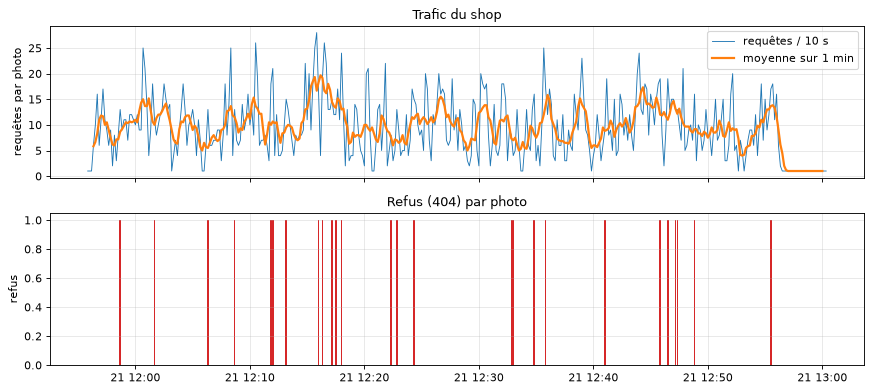

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(df["heure"], df[FEATURE], lw=0.8, label="requêtes / 10 s")
axes[0].plot(df["heure"], df[FEATURE].rolling(6, center=True).mean(), lw=2, label="moyenne sur 1 min")
axes[0].set(title="Trafic du shop", ylabel="requêtes par photo"); axes[0].legend()
axes[1].bar(df["heure"], df[DENIED], width=0.0001, color="tab:red")
axes[1].set(title="Refus (404) par photo", ylabel="refus")
plt.tight_layout(); plt.show()

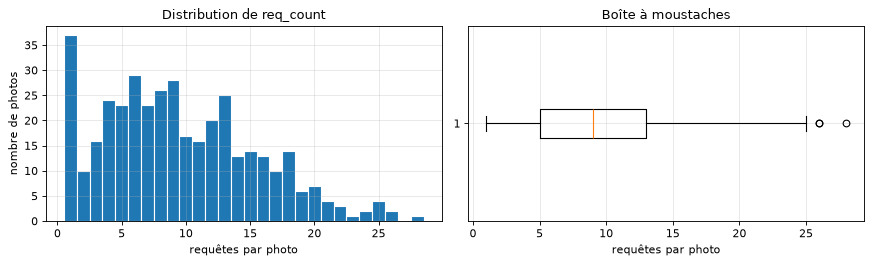

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
valeurs = df[FEATURE].astype(int)
axes[0].hist(valeurs, bins=np.arange(valeurs.min(), valeurs.max() + 2) - 0.5, edgecolor="white")
axes[0].set(title="Distribution de req_count", xlabel="requêtes par photo", ylabel="nombre de photos")
axes[1].boxplot(valeurs, orientation="horizontal")
axes[1].set(title="Boîte à moustaches", xlabel="requêtes par photo")
plt.tight_layout(); plt.show()

**Deux observations utiles pour la suite** :

- Au début et à la fin, le trafic tombe à ~1 requête par photo : le générateur n'a pas encore démarré ou vient de
  s'arrêter, il ne reste que le bruit de fond du front. Pour le test, on isole la **partie active**.
- `non_success_count` est **identique** à `denied_count` (seuls des refus 404 existent) et le nombre de points
  distincts est faible : cela posera un problème à LOF (section 3).

## 2. Partie active, découpe entraînement / test

La partie active est la période où la moyenne glissante sur 1 minute dépasse 4 requêtes. Découpe **dans le temps** :
75 % pour entraîner, 25 % (les plus récentes) pour tester sur du trafic jamais vu.

In [5]:
actif = df.index[df[FEATURE].rolling(6, min_periods=1).mean() > 4]
active = df.loc[actif.min():actif.max()].reset_index(drop=True)
cols = ["timestamp", *mesures]
coupure = int(len(active) * 0.75)
entrainement = active.loc[:coupure - 1, cols].reset_index(drop=True)
test = active.loc[coupure:, cols].set_index("timestamp")
print(f"partie active : {len(active)} photos | entraînement : {len(entrainement)} | test : {len(test)}")

partie active : 362 photos | entraînement : 271 | test : 91


## 3. LOF face aux points identiques

LOF compare la **densité locale** de chaque point à celle de ses voisins (20 par défaut). Si plus de 20 photos sont
exactement identiques, leurs distances sont nulles, la densité devient infinie et le score se fige. Les photos du
trafic réel sont des **compteurs entiers** : beaucoup se répètent. Vérification :

In [6]:
X = entrainement[mesures]
X = X.loc[:, X.std() > 0]
distincts = X.drop_duplicates()
print(f"{len(distincts)} points distincts sur {len(X)} photos d'entraînement")
print("photo la plus répétée :", X.value_counts().iloc[0], "fois (LOF regarde 20 voisins)")
X.value_counts().head(5).to_frame("photos")

39 points distincts sur 271 photos d'entraînement
photo la plus répétée : 23 fois (LOF regarde 20 voisins)


,,,photos
basecamp-shop__req_count,basecamp-shop__denied_count,basecamp-shop__non_success_count,
6.0,0.0,0.0,23
9.0,0.0,0.0,20
4.0,0.0,0.0,19
8.0,0.0,0.0,17
5.0,0.0,0.0,17


In [7]:
# Même LOF, entraîné cette fois sur TOUT normal.csv (avec les photos au repos à 1 requête) : le score se fige ?
complet = df[["timestamp", *mesures]].drop(columns="timestamp")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    lof_complet = AnomalyDetector("lof").fit(complet)
scores_complets = lof_complet.score(test.copy())[COLONNE_SCORE]
print("LOF entraîné sur le fichier complet : score sur le test, min =", scores_complets.min(),
      "| max =", scores_complets.max(), "| valeurs distinctes :", scores_complets.nunique())
print("photos au repos (1 req, 0 refus) dans le fichier complet :",
      int(((df[FEATURE] == 1) & (df[DENIED] == 0)).sum()))

[info] colonnes ignorées car constantes : ['basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
LOF entraîné sur le fichier complet : score sur le test, min = 84112046.56302547 | max = 925232512.2447441 | valeurs distinctes : 11
photos au repos (1 req, 0 refus) dans le fichier complet : 37


Pour comparer LOF honnêtement, on ajoute une variante **`lof_bruit`** : même algorithme, mais avec un très léger
bruit gaussien sur les données d'entraînement (écart-type 0,05 après normalisation) pour séparer les points identiques.
Le LOF du code (`lof`) reste inchangé : on compare les deux.

In [8]:
class LOFBruit(registre.LOFModele):
    """LOF avec un bruit infime à l'entraînement pour éviter les distances nulles (usage notebook uniquement)."""
    BRUIT = 0.05

    def fit(self, X):
        self.colonnes = [c for c in X.columns if X[c].std() > 0]
        self.scaler = StandardScaler().fit(X[self.colonnes])
        Z = self.scaler.transform(X[self.colonnes])
        Z = Z + np.random.default_rng(0).normal(0, self.BRUIT, Z.shape)
        self.modele = LocalOutlierFactor(**self.params).fit(Z)
        return self

registre.MODELES_DISPONIBLES["lof_bruit"] = LOFBruit

## 4. Entraînement des modèles

In [9]:
NOMS = ("isolation_forest", "lof", "lof_bruit", "statistique")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    detecteurs = {nom: AnomalyDetector(nom).fit(entrainement.drop(columns="timestamp")) for nom in NOMS}
print("Mesures apprises :", detecteurs["isolation_forest"].features_par_service[SERVICE])

[info] colonnes ignorées car constantes : ['basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']


Mesures apprises :

 ['basecamp-shop__req_count', 'basecamp-shop__denied_count', 'basecamp-shop__non_success_count']


## 5. Quatre scénarios d'incident

Chaque scénario modifie une fenêtre de photos du jeu de test (trafic réel jamais vu à l'entraînement) :

| Scénario | Ce qui change |
|---|---|
| **flood** | trafic ×8 + 20 requêtes pendant 5 min |
| **scan** | trafic ×3 + 10 et 60 % de refus (un robot teste des adresses inexistantes) pendant 5 min |
| **panne 30 s** | 0 requête pendant 3 photos |
| **panne 60 s** | 0 requête pendant 6 photos |

Les paramètres sont modifiables (`DEBUT`).

In [10]:
DEBUT = 25   # numéro de la photo du jeu de test où l'incident commence

def _etiqueter(base, debut, duree):
    inc = base.copy()
    fenetre = inc.index[debut:debut + duree]
    inc["_verite"] = ""
    inc.loc[fenetre, "_verite"] = SERVICE
    return inc, fenetre

def flood(base, debut=DEBUT, duree=30):
    inc, f = _etiqueter(base, debut, duree)
    inc.loc[f, FEATURE] = (inc.loc[f, FEATURE] * 8 + 20).round()
    return inc, f

def scan(base, debut=DEBUT, duree=30):
    inc, f = _etiqueter(base, debut, duree)
    inc.loc[f, FEATURE] = (inc.loc[f, FEATURE] * 3 + 10).round()
    inc.loc[f, DENIED] = (inc.loc[f, FEATURE] * 0.6).round()
    inc.loc[f, NON_SUCCESS] = inc.loc[f, DENIED]
    return inc, f

def panne(duree):
    def _panne(base, debut=DEBUT):
        inc, f = _etiqueter(base, debut, duree)
        inc.loc[f, [FEATURE, DENIED, NON_SUCCESS]] = 0
        return inc, f
    return _panne

SCENARIOS = {"flood": flood, "scan": scan, "panne 30 s": panne(3), "panne 60 s": panne(6)}
incidents = {nom: fabrique(test) for nom, fabrique in SCENARIOS.items()}

## 6. Les scores au fil du temps

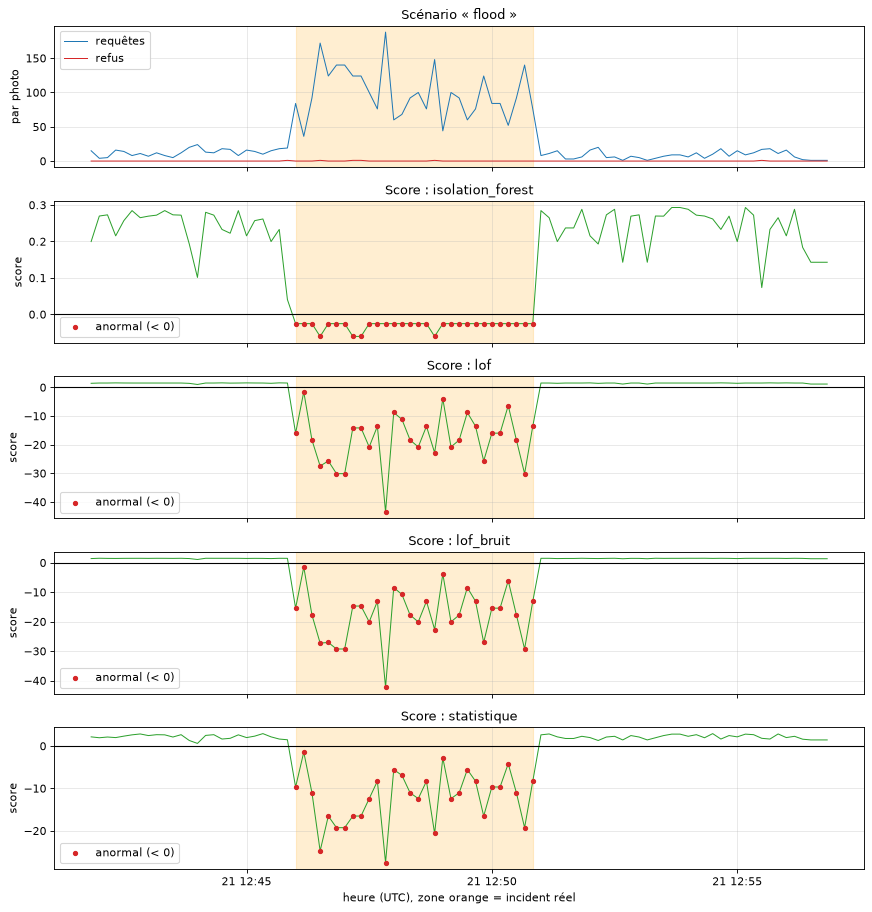

In [11]:
def tracer(nom_scenario):
    inc, fenetre = incidents[nom_scenario]
    temps = pd.to_datetime(inc.index, unit="s", utc=True)
    t0, t1 = temps[inc.index.get_loc(fenetre[0])], temps[inc.index.get_loc(fenetre[-1])]
    fig, axes = plt.subplots(len(NOMS) + 1, 1, figsize=(11, 2.3 * (len(NOMS) + 1)), sharex=True)
    axes[0].plot(temps, inc[FEATURE], lw=0.9, label="requêtes")
    axes[0].plot(temps, inc[DENIED], lw=0.9, color="tab:red", label="refus")
    axes[0].set(title=f"Scénario « {nom_scenario} »", ylabel="par photo"); axes[0].legend(loc="upper left")
    for ax, nom in zip(axes[1:], NOMS):
        s = detecteurs[nom].score(inc.drop(columns="_verite"))[COLONNE_SCORE]
        ax.plot(temps, s, lw=0.9, color="tab:green")
        ax.axhline(0, color="black", lw=1)
        anormal = (s < 0).to_numpy()
        ax.scatter(temps[anormal], s.to_numpy()[anormal], color="tab:red", s=14, zorder=3, label="anormal (< 0)")
        if s.abs().max() > 1000:
            ax.set_yscale("symlog", linthresh=1)
        ax.set(title=f"Score : {nom}", ylabel="score"); ax.legend(loc="lower left")
    for ax in axes:
        ax.axvspan(t0, t1, color="orange", alpha=0.18)
    axes[-1].set_xlabel("heure (UTC), zone orange = incident réel")
    plt.tight_layout(); plt.show()

tracer("flood")

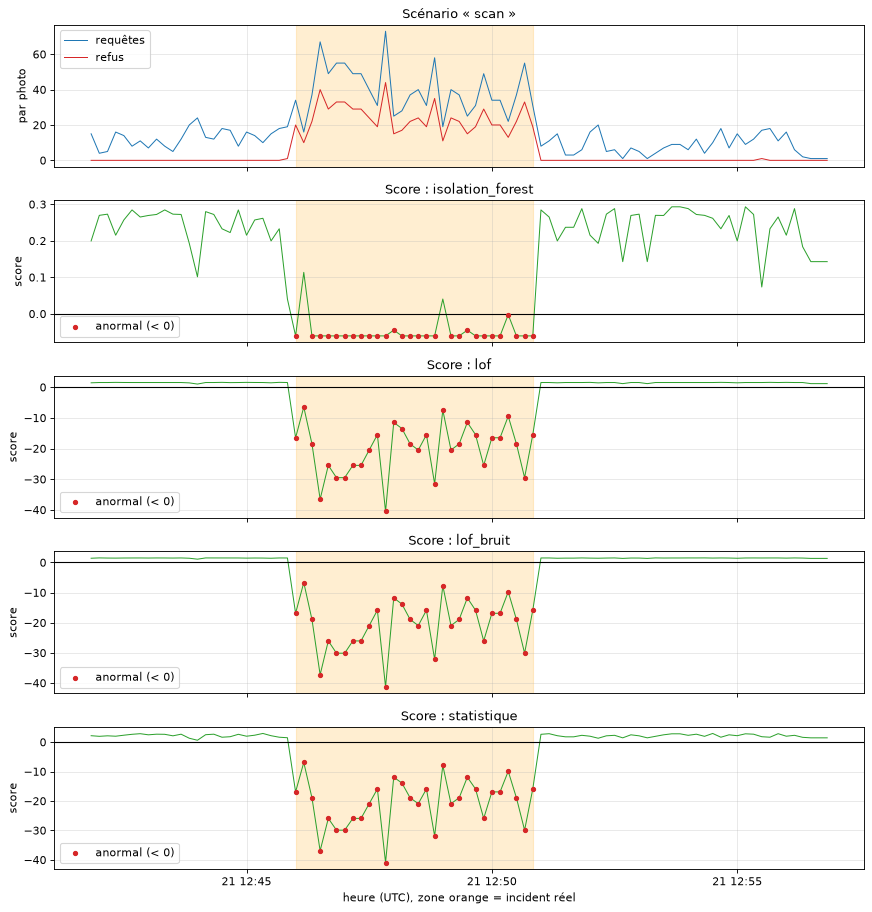

In [12]:
tracer("scan")

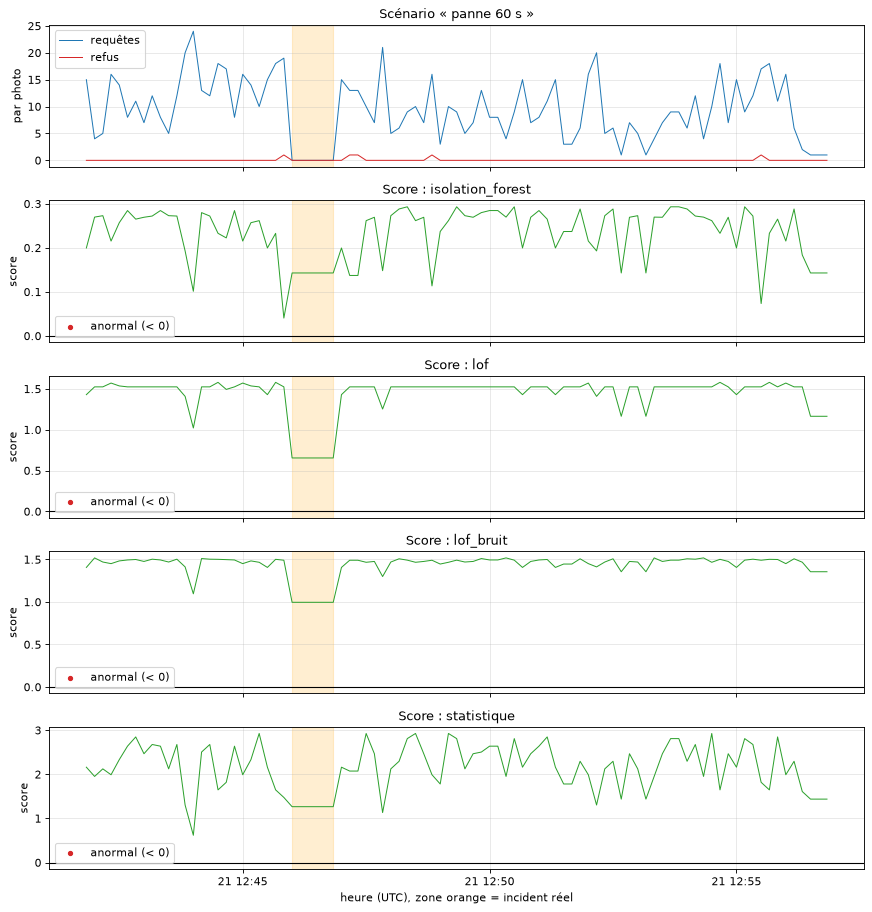

In [13]:
tracer("panne 60 s")

**Comment lire** : la zone orange est l'incident réel. Un bon modèle a ses points rouges (score < 0) **dans** la zone
orange et aucun en dehors. Le LOF du code (`lof`) a un score figé s'il rencontre trop de points identiques.

## 7. Où chaque modèle place-t-il son seuil ?

On fait varier `req_count` seul, les autres mesures (refus) étant fixées à 0. Là où la courbe passe sous 0, le modèle
crie à l'anomalie. Les échelles diffèrent : **comparer les croisements avec 0**, pas les hauteurs.

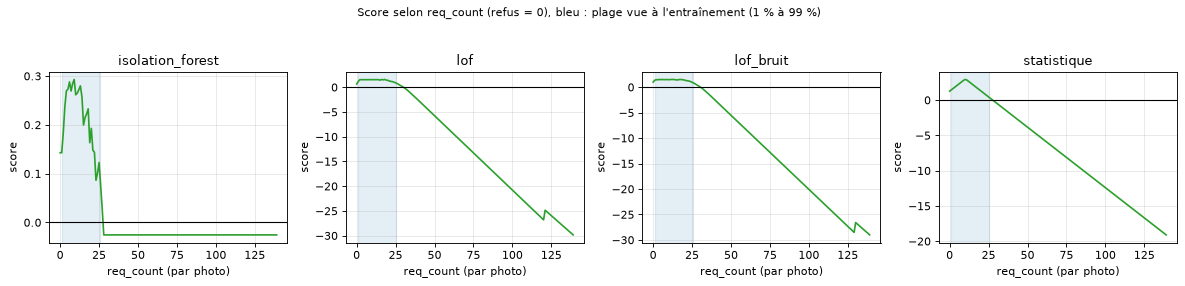

In [14]:
valeurs_req = np.arange(0, 140)
colonnes_service = detecteurs["isolation_forest"].features_par_service[SERVICE]
grille = pd.DataFrame(0.0, index=range(len(valeurs_req)), columns=colonnes_service)
grille[FEATURE] = valeurs_req
bas_normal, haut_normal = entrainement[FEATURE].quantile([0.01, 0.99])

fig, axes = plt.subplots(1, len(NOMS), figsize=(15, 3.4))
for ax, nom in zip(axes, NOMS):
    courbe = detecteurs[nom].modeles[SERVICE].decision_function(grille)
    ax.plot(valeurs_req, courbe, color="tab:green")
    ax.axhline(0, color="black", lw=1)
    ax.axvspan(bas_normal, haut_normal, color="tab:blue", alpha=0.12)
    ax.set(title=nom, xlabel="req_count (par photo)", ylabel="score")
    if np.abs(courbe).max() > 1000:
        ax.set_yscale("symlog", linthresh=1)
plt.suptitle("Score selon req_count (refus = 0), bleu : plage vue à l'entraînement (1 % à 99 %)", y=1.04, fontsize=10)
plt.tight_layout(); plt.show()

## 8. Bilan : fausses alertes et détection par scénario

In [15]:
# Fausses alertes : part des photos NORMALES (jamais vues) jugées anormales
faux = pd.Series({nom: (det.score(test.copy())[COLONNE_SCORE] < 0).mean() * 100 for nom, det in detecteurs.items()},
                 name="% photos normales jugées anormales")
display(faux.round(1).to_frame())

# Détection : délai (en s) avant l'alerte, ou « non détecté » (règle : 3 photos anormales d'affilée)
lignes = {}
for nom_scenario, (inc, _) in incidents.items():
    bilan = comparer(inc, detecteurs, n_consecutifs=config.N_CONSECUTIFS).set_index("modele")
    lignes[nom_scenario] = bilan.apply(
        lambda r: f"{int(r['delai_s'])} s ({r['nb_fausses_alertes']:.0f} fausse alerte)" if r["type"] == "detecte" else "non détecté",
        axis=1)
pd.DataFrame(lignes)

,% photos normales jugées anormales
isolation_forest,0.0
lof,0.0
lof_bruit,0.0
statistique,0.0


,flood,scan,panne 30 s,panne 60 s
modele,,,,
isolation_forest,20 s (0 fausse alerte),40 s (0 fausse alerte),non détecté,non détecté
lof,20 s (0 fausse alerte),20 s (0 fausse alerte),non détecté,non détecté
lof_bruit,20 s (0 fausse alerte),20 s (0 fausse alerte),non détecté,non détecté
statistique,20 s (0 fausse alerte),20 s (0 fausse alerte),non détecté,non détecté


**Constats de l'exécution du 21/10** (données : 388 photos, 3402 requêtes du générateur) :

- 0 fausse alerte pour les quatre modèles sur le trafic normal non vu.
- **flood** : détecté en 20 s par les quatre.
- **scan** (refus) : 20 s pour LOF et statistique, 40 s pour l'Isolation Forest.
- **panne 30 s et 60 s : aucun modèle ne détecte la chute à 0 requête** (voir section 7 : les scores restent positifs
  à 0). Un compteur de 9,5 requêtes en moyenne qui tombe à 0 reste à moins de 2 écarts-types : le modèle ne voit pas
  de différence assez grande. Une panne se détecte mieux avec une règle « silence » ou les healthchecks.
- **LOF** : fonctionne sur la partie active, mais se fige s'il est entraîné sur le fichier complet (cellule de la
  section 3). Il n'est donc fiable qu'avec des données d'entraînement choisies avec soin.

**Pour la suite** (à adapter selon vos résultats) :

- Un modèle est bon s'il détecte les quatre scénarios avec **0 fausse alerte**.
- Une **panne de 30 s** (3 photos) est à la limite de la règle des 3 photos d'affilée : le moindre décalage la rend
  indétectable. Une **chute à zéro** n'est détectable que si 0 est rare dans l'entraînement.
- Les différences entre modèles apparaîtront davantage quand `auth` et `payment` donneront plusieurs mesures par service.

**Limites** : les incidents sont injectés dans du trafic réel, pas de vraies attaques ; pas de cycle jour/nuit ;
un seul service ; un seul jeu de test d'environ 15 minutes.